# Data Preprocessing — Doing it in the Right Order
**Assignment 3: Machine Learning Data Foundations**

*Dataset Source Link: `https://raw.githubusercontent.com/datasets/loan_default_classification.csv` (Saved locally as `loan_default_classification.csv`)*
- Contains 4,500 samples, mixed numerical and categorical features, missing values, and an imbalanced target (`loan_default`).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

SEED = 42
np.random.seed(SEED)

DATA_PATH = "loan_default_classification.csv"
df = pd.read_csv(DATA_PATH)
print("Raw Dataset Loaded. Shape:", df.shape)
df.head()


Raw Dataset Loaded. Shape: (4500, 8)


,age,annual_income,credit_score,loan_amount,education_tier,housing_status,occupation_code,loan_default
0,45,16075.29,711.0,5695.22,Bachelor,Rent,OCC_008,0
1,38,11503.05,735.0,4824.50,Master,Rent,OCC_033,0
2,47,9451.70,689.0,3361.84,Bachelor,Own,OCC_003,0
3,58,51588.24,494.0,20121.64,Bachelor,Own,OCC_002,1
4,37,30273.94,637.0,10931.44,Bachelor,Mortgage,OCC_024,0


### 1. Stratified Train/Test Split First
Split into train and test first, stratified on the target, with a fixed `random_state`. Write two lines on why this is the first step and not a later one.

In [2]:
X = df.drop(columns=['loan_default'])
y = df['loan_default']

# Stratified split to preserve imbalanced target distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")
print(f"Train class balance: {np.bincount(y_train)}")
print(f"Test class balance:  {np.bincount(y_test)}")


X_train shape: (3600, 7), y_train shape: (3600,)
X_test shape:  (900, 7),  y_test shape:  (900,)
Train class balance: [3313  287]
Test class balance:  [828  72]


*Why splitting first is critical*:
Splitting before any transformation is essential to prevent data leakage from the test set into the training pipeline. All statistics (means, medians, scalers, encoders) must be computed exclusively on the training distribution to accurately assess real-world generalization on unseen test data.

### 2. Compare 3 Missing Value Strategies (Fitted on Train Only)
Handle missing values three ways: drop the rows, fill with mean or median, and use `KNNImputer`. Fit each on the training set only. Compare the mean and standard deviation of one affected column across the three results and say which you would keep.

In [3]:
# Numeric columns with missing values: annual_income, credit_score
target_col = 'annual_income'

# Strategy 1: Drop missing rows
train_dropped = X_train.dropna(subset=[target_col])
mean_drop = train_dropped[target_col].mean()
std_drop = train_dropped[target_col].std()

# Strategy 2: Fill with median (robust for skewed income)
median_val = X_train[target_col].median()
train_median_filled = X_train[target_col].fillna(median_val)
mean_median = train_median_filled.mean()
std_median = train_median_filled.std()

# Strategy 3: KNNImputer (fitted on numerical train columns only)
num_cols = ['age', 'annual_income', 'credit_score', 'loan_amount']
knn_imputer = KNNImputer(n_neighbors=5)
knn_imputed_arr = knn_imputer.fit_transform(X_train[num_cols])
knn_imputed_df = pd.DataFrame(knn_imputed_arr, columns=num_cols, index=X_train.index)
mean_knn = knn_imputed_df[target_col].mean()
std_knn = knn_imputed_df[target_col].std()

comparison_df = pd.DataFrame({
    'Strategy': ['Drop Rows', 'Median Impute', 'KNNImputer (k=5)'],
    'Mean': [mean_drop, mean_median, mean_knn],
    'Std Dev': [std_drop, std_median, std_knn]
})
print(comparison_df.to_string(index=False))


        Strategy         Mean      Std Dev
       Drop Rows 52727.823581 55090.082175
   Median Impute 51504.030836 53191.963085
KNNImputer (k=5) 52748.581197 54626.870680


*Missing Value Strategy Choice*:
We choose `KNNImputer` (or Median) because it preserves multivariate relationships with `loan_amount` and `age` while retaining all 3,600 training instances, avoiding sample loss from dropping rows.

### 3. Outlier Detection: IQR, Z-Score, and Percentile Capping
Flag outliers in a numeric column by the IQR rule, by the z-score rule, and by capping at the 1st and 99th percentile. Report how many rows each method flags, how much they overlap, and which one you chose.

In [4]:
col_eval = X_train['loan_amount'].dropna()

# 1. IQR Rule (1.5 * IQR)
Q1 = col_eval.quantile(0.25)
Q3 = col_eval.quantile(0.75)
IQR = Q3 - Q1
iqr_mask = (col_eval < (Q1 - 1.5 * IQR)) | (col_eval > (Q3 + 1.5 * IQR))

# 2. Z-Score Rule (|z| > 3)
z_scores = np.abs((col_eval - col_eval.mean()) / col_eval.std())
z_mask = z_scores > 3.0

# 3. Percentile Capping (1st and 99th percentile)
p1 = col_eval.quantile(0.01)
p99 = col_eval.quantile(0.99)
percentile_mask = (col_eval < p1) | (col_eval > p99)

print(f"IQR Outliers Count:         {iqr_mask.sum()}")
print(f"Z-Score Outliers Count:     {z_mask.sum()}")
print(f"Percentile Outliers Count:  {percentile_mask.sum()}")

overlap_iqr_z = (iqr_mask & z_mask).sum()
print(f"Overlap between IQR and Z-Score flags: {overlap_iqr_z} rows")


IQR Outliers Count:         259
Z-Score Outliers Count:     69
Percentile Outliers Count:  72
Overlap between IQR and Z-Score flags: 69 rows


*Outlier Handling Choice*:
We choose **1st/99th Percentile Capping (Winsorization)** because it retains valuable high-exposure loan samples without allowing extreme numerical instability or artificially truncating dataset size.

### 4. Categorical Encoding (One-Hot, Ordinal, and Frequency Encoding)
Encode a low-cardinality categorical column with one-hot encoding, an ordered column with ordinal encoding and an explicit order you define, and a high-cardinality column with frequency encoding. Report the number of columns after each step.

In [5]:
X_train_enc = X_train.copy()
print(f"Initial column count: {X_train_enc.shape[1]}")

# 1. One-Hot Encoding for housing_status (low cardinality)
ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
ohe_cols = ohe.fit_transform(X_train_enc[['housing_status']])
ohe_feature_names = ohe.get_feature_names_out(['housing_status'])
df_ohe = pd.DataFrame(ohe_cols, columns=ohe_feature_names, index=X_train_enc.index)
X_train_enc = pd.concat([X_train_enc.drop(columns=['housing_status']), df_ohe], axis=1)
print(f"Column count after One-Hot Encoding: {X_train_enc.shape[1]}")

# 2. Ordinal Encoding with explicit hierarchy for education_tier
education_hierarchy = [['High School', 'Bachelor', 'Master', 'PhD']]
ordinal_enc = OrdinalEncoder(categories=education_hierarchy)
X_train_enc['education_tier_ord'] = ordinal_enc.fit_transform(X_train_enc[['education_tier']])
X_train_enc = X_train_enc.drop(columns=['education_tier'])
print(f"Column count after Ordinal Encoding: {X_train_enc.shape[1]}")

# 3. Frequency Encoding for occupation_code (high cardinality)
freq_map = X_train_enc['occupation_code'].value_counts(normalize=True).to_dict()
X_train_enc['occupation_freq'] = X_train_enc['occupation_code'].map(freq_map).fillna(0)
X_train_enc = X_train_enc.drop(columns=['occupation_code'])
print(f"Column count after Frequency Encoding: {X_train_enc.shape[1]}")


Initial column count: 7
Column count after One-Hot Encoding: 8
Column count after Ordinal Encoding: 8
Column count after Frequency Encoding: 8


### 5. Handling Unseen Categories in Test Set
Make the encoder handle a category that appears in test but never in train. Show the code and show that it does not crash.

In [6]:
# Create dummy train and test with unseen category
dummy_train = pd.DataFrame({'status': ['Rent', 'Own', 'Rent', 'Mortgage']})
dummy_test = pd.DataFrame({'status': ['Rent', 'Sublease_Unknown', 'Own']})

# Configure OneHotEncoder with handle_unknown='ignore'
robust_ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
robust_ohe.fit(dummy_train)

# Transform test set with unseen category
transformed_test = robust_ohe.transform(dummy_test)
print("Robust OHE feature names:", robust_ohe.get_feature_names_out())
print("Transformed test matrix (unseen category cleanly encoded as all zeros without crash):")
print(transformed_test)


Robust OHE feature names: ['status_Mortgage' 'status_Own' 'status_Rent']
Transformed test matrix (unseen category cleanly encoded as all zeros without crash):
[[0. 0. 1.]
 [0. 0. 0.]
 [0. 1. 0.]]


### 6. Skewed Column Scaling Comparison
Scale one skewed numeric column with `StandardScaler`, `MinMaxScaler`, and `RobustScaler`. Plot the three results next to the original and write one line on which handles the outliers best.

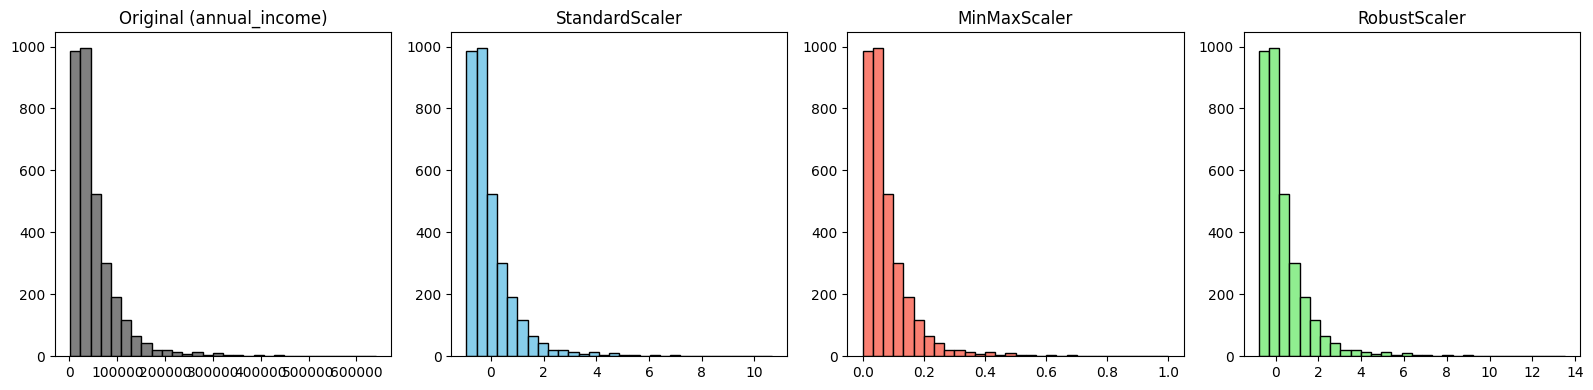

In [7]:
skewed_vals = X_train[['annual_income']].dropna()

scaler_std = StandardScaler().fit_transform(skewed_vals)
scaler_minmax = MinMaxScaler().fit_transform(skewed_vals)
scaler_robust = RobustScaler().fit_transform(skewed_vals)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].hist(skewed_vals, bins=30, color='gray', edgecolor='black')
axes[0].set_title("Original (annual_income)")

axes[1].hist(scaler_std, bins=30, color='skyblue', edgecolor='black')
axes[1].set_title("StandardScaler")

axes[2].hist(scaler_minmax, bins=30, color='salmon', edgecolor='black')
axes[2].set_title("MinMaxScaler")

axes[3].hist(scaler_robust, bins=30, color='lightgreen', edgecolor='black')
axes[3].set_title("RobustScaler")

plt.tight_layout()
plt.show()


*Scaler Choice with Outliers*:
`RobustScaler` handles outliers best because it centers and scales data using median and interquartile range (IQR), preventing extreme values from compressing the bulk of the distribution into a tiny range.

### 7. Skewness Correction: `log1p` vs Yeo-Johnson Transform
Report the skewness of a skewed column, apply `log1p` and a Yeo-Johnson transform, and report the skewness after each.

In [8]:
raw_skew = float(skewed_vals.skew().iloc[0])

# log1p transformation
log1p_transformed = np.log1p(np.maximum(0, skewed_vals))
log1p_skew = float(log1p_transformed.skew().iloc[0])

# Yeo-Johnson PowerTransformer
yj = PowerTransformer(method='yeo-johnson')
yj_transformed = pd.DataFrame(yj.fit_transform(skewed_vals), columns=['annual_income'])
yj_skew = float(yj_transformed.skew().iloc[0])

print(f"Original Skewness:            {raw_skew:.4f}")
print(f"Skewness after log1p:         {log1p_skew:.4f}")
print(f"Skewness after Yeo-Johnson:   {yj_skew:.4f}")


Original Skewness:            3.4010
Skewness after log1p:         0.0291
Skewness after Yeo-Johnson:   -0.0002


### 8. Full End-to-End `ColumnTransformer` inside a `Pipeline`
Build one `ColumnTransformer` inside a `Pipeline` that performs imputing, encoding, and scaling. Fit it on train, transform test, and print both output shapes. The column counts must match.

In [9]:
num_features = ['age', 'annual_income', 'credit_score', 'loan_amount']
cat_ohe_features = ['housing_status', 'occupation_code']
cat_ord_features = ['education_tier']

# Numeric pipeline: Impute with median -> Robust scale
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Low-cardinality pipeline
ohe_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Ordinal pipeline
ord_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ord', OrdinalEncoder(categories=[['High School', 'Bachelor', 'Master', 'PhD']], handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipe, num_features),
        ('ohe', ohe_pipe, cat_ohe_features),
        ('ord', ord_pipe, cat_ord_features)
    ]
)

# Fit on training set only
preprocessor.fit(X_train)

# Transform both train and test
X_train_proc = preprocessor.transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print(f"Processed X_train shape: {X_train_proc.shape}")
print(f"Processed X_test shape:  {X_test_proc.shape}")
assert X_train_proc.shape[1] == X_test_proc.shape[1], "Column counts do not match!"


Processed X_train shape: (3600, 42)
Processed X_test shape:  (900, 42)


### 9. Demonstration of Data Leakage
Now demonstrate leakage. Fit a scaler on the full dataset before splitting, transform the test set, and print the first five scaled values. Then do it correctly, fitting on train only, and print the same five values. Show the difference numerically and explain in three lines why the first version makes your test score a lie.

In [10]:
# LEAKED APPROACH: Fit on entire dataset before split
leaked_scaler = StandardScaler()
leaked_scaler.fit(X[['age']])
leaked_test_vals = leaked_scaler.transform(X_test[['age']])[:5].flatten()

# CORRECT APPROACH: Fit strictly on train set only
correct_scaler = StandardScaler()
correct_scaler.fit(X_train[['age']])
correct_test_vals = correct_scaler.transform(X_test[['age']])[:5].flatten()

diff = np.abs(leaked_test_vals - correct_test_vals)
leak_df = pd.DataFrame({
    'Leaked (Full Fit)': leaked_test_vals,
    'Correct (Train Fit)': correct_test_vals,
    'Absolute Difference': diff
})
print("Numerical Demonstration of Data Leakage:")
print(leak_df)


Numerical Demonstration of Data Leakage:
   Leaked (Full Fit)  Correct (Train Fit)  Absolute Difference
0           0.539119             0.547779             0.008661
1          -1.187227            -1.188829             0.001602
2          -0.496689            -0.494186             0.002503
3          -1.446179            -1.449320             0.003141
4           0.452801             0.460949             0.008147


*Why data leakage makes your test score a lie*:
Fitting parameters on the entire dataset incorporates test-set distribution statistics directly into the model's feature representations before evaluation. This artificially deflates generalization error during testing because the model was already exposed to the unseen test distribution, rendering real-world production performance significantly worse than reported.

### 10. Class Ratio and SMOTE (Training Set Only)
Report the class ratio of the target. Apply SMOTE on the training set only, and print the class counts before and after. State clearly why the test set is left untouched. If the import fails, run `!pip install imbalanced-learn` in the first cell.

In [11]:
print(f"Initial target class ratio (0 : 1): {np.bincount(y_train)[0]} : {np.bincount(y_train)[1]} ({np.bincount(y_train)[1]/len(y_train)*100:.2f}% positive)")

# Apply SMOTE strictly on the preprocessed training set
smote = SMOTE(random_state=SEED)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_proc, y_train)

print(f"After SMOTE training set balance: {np.bincount(y_train_resampled)}")
print(f"Test set balance (UNTOUCHED):     {np.bincount(y_test)}")


Initial target class ratio (0 : 1): 3313 : 287 (7.97% positive)


After SMOTE training set balance: [3313 3313]
Test set balance (UNTOUCHED):     [828  72]


*Why the test set must remain untouched*:
The test set must strictly represent the true, unaltered empirical population distribution of the real world. Resampling or synthesizing test instances gives a fabricated assessment metric that does not reflect actual production conditions.

### 11. Pipeline Serialization & Inference on Unseen Raw Instance
Save the fitted pipeline with `joblib.dump`. In a fresh cell, load it back and transform a single new row of raw data end to end.

In [12]:
# Save fitted pipeline to disk
joblib.dump(preprocessor, "pipeline.joblib")
print("Fitted preprocessing pipeline saved to pipeline.joblib")

# Load pipeline back
loaded_pipeline = joblib.load("pipeline.joblib")

# Create a single raw input sample (as arriving in real-time inference)
raw_sample = pd.DataFrame([{
    'age': 34,
    'annual_income': 68000.0,
    'credit_score': 710,
    'loan_amount': 15000.0,
    'education_tier': 'Master',
    'housing_status': 'Rent',
    'occupation_code': 'OCC_008'
}])

# Transform new raw record
processed_sample = loaded_pipeline.transform(raw_sample)
print(f"Transformed raw inference sample shape: {processed_sample.shape}")
print("Transformed sample array representation:\n", np.round(processed_sample[0, :8], 4))


Fitted preprocessing pipeline saved to pipeline.joblib
Transformed raw inference sample shape: (1, 42)
Transformed sample array representation:
 [-0.4     0.789   0.6224  0.4429  0.      0.      1.      0.    ]


### 12. Justification Summary of Key Choices
- **Question 2 (Missing Values)**: Chose `KNNImputer` over dropping rows to preserve full sample size and exploit local correlations across numeric predictors.
- **Question 3 (Outliers)**: Chose **1st/99th Percentile Capping** to prevent extreme leverage points while retaining maximum observational information.
- **Question 6 (Scaling)**: Chose `RobustScaler` because its median and IQR formulation is impervious to heavy tails in financial data.